In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import time
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Raw windows (24 features)
X_train_raw = np.load("../data/processed/elia_X_train.npy")
X_val_raw   = np.load("../data/processed/elia_X_val.npy")
X_test_raw  = np.load("../data/processed/elia_X_test.npy")

# Learned latent features (8 features)
F_train = np.load("../data/processed/elia_F_train.npy")
F_val   = np.load("../data/processed/elia_F_val.npy")
F_test  = np.load("../data/processed/elia_F_test.npy")

# Targets
y_train = np.load("../data/processed/elia_y_train.npy")
y_val   = np.load("../data/processed/elia_y_val.npy")
y_test  = np.load("../data/processed/elia_y_test.npy")

print("Raw:     ", X_train_raw.shape, X_val_raw.shape, X_test_raw.shape)
print("Latent:  ", F_train.shape,     F_val.shape,     F_test.shape)
print("Targets: ", y_train.shape,     y_val.shape,     y_test.shape)

Raw:      (33700, 24) (7221, 24) (7222, 24)
Latent:   (33700, 8) (7221, 8) (7222, 8)
Targets:  (33700,) (7221,) (7222,)


In [2]:
def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100

def evaluate(name, y_true, y_pred, latency_ms, n_features):
    return {
        "model": name,
        "n_features": n_features,
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE":  float(mean_absolute_error(y_true, y_pred)),
        "MAPE": float(mape(y_true, y_pred)),
        "R2":   float(r2_score(y_true, y_pred)),
        "latency_ms": float(latency_ms),
    }

def train_and_eval(name, X_train, X_test, y_train, y_test, n_features):
    rf = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
    rf.fit(X_train, y_train)
    t0 = time.perf_counter()
    y_pred = rf.predict(X_test)
    latency = ((time.perf_counter() - t0) / len(X_test)) * 1000
    metrics = evaluate(name, y_test, y_pred, latency, n_features)
    return metrics, y_pred

In [3]:
results = []
preds = {}

# A: Raw features only (24)
m, p = train_and_eval("A. Raw features", X_train_raw, X_test_raw, y_train, y_test, 24)
results.append(m); preds["raw"] = p
print(m)

# B: Learned latent only (8)
m, p = train_and_eval("B. Latent features", F_train, F_test, y_train, y_test, 8)
results.append(m); preds["latent"] = p
print(m)

# C: Raw + Latent concatenated (32)
X_train_both = np.hstack([X_train_raw, F_train])
X_test_both  = np.hstack([X_test_raw,  F_test])
m, p = train_and_eval("C. Raw + Latent", X_train_both, X_test_both, y_train, y_test, 32)
results.append(m); preds["both"] = p
print(m)

{'model': 'A. Raw features', 'n_features': 24, 'RMSE': 191.69633654498392, 'MAE': 143.9811006635865, 'MAPE': 1.502305497888163, 'R2': 0.9800397598327099, 'latency_ms': 0.030174591526219156}
{'model': 'B. Latent features', 'n_features': 8, 'RMSE': 321.6009530574176, 'MAE': 245.98676624775308, 'MAPE': 2.558306702536546, 'R2': 0.9438211570651482, 'latency_ms': 0.029991235115441692}
{'model': 'C. Raw + Latent', 'n_features': 32, 'RMSE': 192.0912782523024, 'MAE': 144.26297758034377, 'MAPE': 1.5049769545792517, 'R2': 0.9799574290790891, 'latency_ms': 0.02739127665462565}


In [4]:
results_df = pd.DataFrame(results).set_index("model")
print("\n=== Feature Comparison on ELIA Grid Data ===\n")
display(results_df.round(4))


=== Feature Comparison on ELIA Grid Data ===



,n_features,RMSE,MAE,MAPE,R2,latency_ms
model,,,,,,
A. Raw features,24,191.6963,143.9811,1.5023,0.9800,0.0302
B. Latent features,8,321.6010,245.9868,2.5583,0.9438,0.0300
C. Raw + Latent,32,192.0913,144.2630,1.5050,0.9800,0.0274


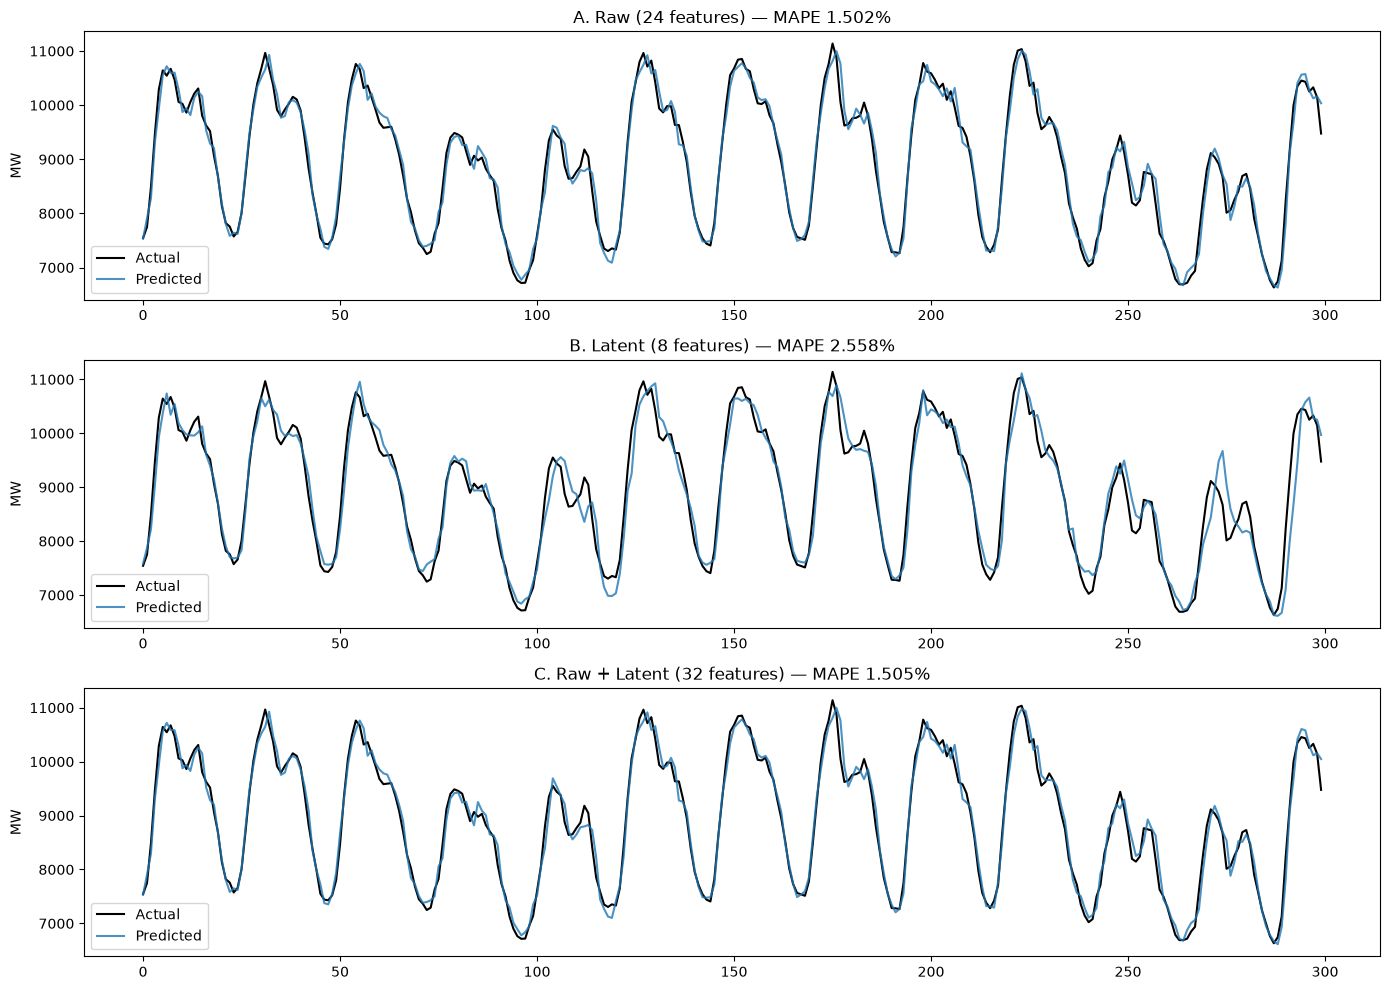

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

for ax, (key, label) in zip(
    axes,
    [("raw", "A. Raw (24 features)"),
     ("latent", "B. Latent (8 features)"),
     ("both", "C. Raw + Latent (32 features)")]
):
    ax.plot(y_test[:300], label="Actual", linewidth=1.5, color="black")
    ax.plot(preds[key][:300], label="Predicted", linewidth=1.5, alpha=0.8)
    metrics = next(r for r in results if r["model"].startswith(label[0]))
    ax.set_title(f"{label} — MAPE {metrics['MAPE']:.3f}%")
    ax.set_ylabel("MW")
    ax.legend()

plt.tight_layout()
plt.savefig("../data/processed/feature_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
comparison = {
    "A_raw_features":    results[0],
    "B_latent_features": results[1],
    "C_raw_plus_latent": results[2],
}
with open("../data/processed/feature_comparison.json", "w") as f:
    json.dump(comparison, f, indent=2)

print("Saved feature_comparison.json")

Saved feature_comparison.json
